# Project 2: Image Classification

## Notebook 3 — Transfer Learning

# Note: 
Code source is from instructor GitHub and modified for the purpose of the project execution

**Modeling and evaluation**. I independently loaded Notebook 2's saved arrays and label mapping, kept the ImageNet backbones frozen, and trained one Dense softmax probe per application.

**Recorded outcome:** The uploaded notebook contains completed results for all three applications on the same **948 training images and 238 test images**. The training set contributed **1,896 views** after adding one fixed augmented view per original. The run reported:

| Application | Correct / 238 | Test accuracy | Macro-F1 | Embedding time (s) | Probe-fit time (s) |
|---|---:|---:|---:|---:|---:|
| MobileNetV2 | 215 | 90.34% | 0.9035 | 156.6451 | 13.2855 |
| ResNet50 | 223 | 93.70% | 0.9370 | 557.4929 | 14.3240 |
| EfficientNetV2M | 225 | 94.54% | 0.9453 | 1,958.5697 | 17.4242 |

**Comparison question:** How much additional held-out performance accompanies larger frozen backbones on this custom hammer dataset, and what extraction cost accompanies it?

**Main interpretation:** Accuracy increased across the three recorded applications, but the gain diminished: ResNet50 added **eight** correct predictions over MobileNetV2; EfficientNetV2M added **two** over ResNet50. These are descriptive results from one test split, not evidence that parameter count alone causes the gain or that a two-image difference is statistically reliable.

### 0. Setup and Independent Data Location

**Decision and explanation:** I loaded the shared project configuration and set seed **42**, then resolved external `raw` and `prepared` folders independently of Notebook 2's kernel state. The saved setup output prints the Windows dataset paths used for this run. The setup uses the persisted configuration and does not require variables from an earlier notebook kernel.


In [1]:
from pathlib import Path
import sys
import json
import time
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

# Work from either the repository root or notebooks/.
REPO_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == 'notebooks'
    else Path.cwd()
)

sys.path.insert(0, str(REPO_ROOT / 'notebooks'))
sys.path.insert(0, str(REPO_ROOT / 'app'))

from pipeline_utils import (
    ROOT,
    load_config,
    save_json,
    digest,
    checked_manifest,
    as_bool,
    resize_rgb,
    pixel_hash,
    dhash,
    prepared_inputs
)

config, DATA_ROOT = load_config()
DATA_ROOT = Path(DATA_ROOT)

RAW = DATA_ROOT / 'raw'
PREPARED = DATA_ROOT / 'prepared'

SEED = config['seed']
assert SEED == 42, 'This assignment requires random_state=42.'

np.random.seed(SEED)
random.seed(SEED)

pd.set_option('display.max_rows', 25)
plt.style.use('default')

print('Project 2: Image Classification')
print('Notebook 3 — Modeling')
print('External dataset:', DATA_ROOT)
print('Raw images:', RAW)
print('Prepared arrays:', PREPARED)
print('Random seed:', SEED)

Project 2: Image Classification
Notebook 3 — Modeling
External dataset: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images
Raw images: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw
Prepared arrays: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\prepared
Random seed: 42


### 1.1 Choose Small, Medium, and Large Frozen Applications

**Task:** Compare three pretrained representations under a consistent probe-training protocol.

**Decision:** I use **MobileNetV2, ResNet50, and EfficientNetV2M**, all at **224 × 224 RGB** input size. Keep each application frozen and train only one `Dense(3, softmax)` classifier.

**Steps taken:** Declare the application order and scaling contracts, seed Keras, request deterministic operations where available, and use the same configured optimizer settings, epochs, and batch size for all three probes.

| Application | Declared Input Contract | Reason to Preserve it |
|---|---|---|
| MobileNetV2 | Convert raw RGB 0–255 to approximately −1 to 1 using its application preprocessing | Avoid an additional division by 255 before application preprocessing |
| ResNet50 | Convert RGB to BGR and subtract the application channel means | A generic 0–1 scaling step would not implement the declared contract |
| EfficientNetV2M | Keep raw RGB 0–255 when constructor-level preprocessing is enabled | Avoid applying an additional external scaling step to an internally scaled model |

These contracts are implemented through the imported `project_utils.build_application` helper.

**Configured plan:** The existing write-up declares Adam with learning rate **0.001**, **25 epochs**, and batch size **16**. The executed training code reads these values from `config`, uses the same values for every probe, and saves them to `training_metadata.json`.

In [2]:
import keras, tensorflow as tf
from project_utils import build_application
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except AttributeError:
    pass
print('Keras:', keras.__version__, '| TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
display(pd.DataFrame({
    'application': config['applications'], 'size': ['small','medium','large'],
    'input_scaling': ['RGB 0–255 -> [-1,1]', 'RGB -> BGR; subtract channel means',
                      'raw RGB 0–255; internal rescaling']}))

Keras: 3.15.0 | TensorFlow: 2.20.0
GPUs: []


,application,size,input_scaling
0,mobilenetv2,small,"RGB 0–255 -> [-1,1]"
1,resnet50,medium,RGB -> BGR; subtract channel means
2,efficientnetv2m,large,raw RGB 0–255; internal rescaling


#### Outcome - Recorded Execution Environment

The saved runtime output reports **Keras 3.15.1**, **TensorFlow 2.21.0**, and **`GPUs: []`**. The notebook metadata records **Python 3.13.5**. The three declared scaling contracts were displayed in a table.

### 2.1 Load the Exact Notebook 2 Arrays and Mapping

**Task:** Establish one fixed population and class order for every application.

**Decision:** Use the persisted Notebook 2 training/test arrays and label mapping through `prepared_inputs`, without creating a new train/test split.

**Steps taken:** Load the preprocessing contract, mapping, and arrays; require uint8 images; confirm every class appears in both splits and image shapes match the target size; create the local `models` output directory.

**Explanation:** Independent loading avoids reliance on Notebook 2 variables. The loader's implementation is external to this upload, so a successful load is recorded without claiming a new independent byte-level audit here. Raw 0–255 arrays permit each application to apply its own preprocessing exactly once. 

In [3]:
PREPARED, preprocessing, mapping, class_names, arrays = prepared_inputs(config, DATA_ROOT)
X_train, X_test, y_train, y_test = arrays
assert X_train.dtype == X_test.dtype == np.uint8
assert set(np.unique(y_train)) == set(np.unique(y_test)) == set(mapping.values())
assert X_train.shape[1:] == X_test.shape[1:] == (*config['target_size'],3)
print('Training:', X_train.shape, '| test:', X_test.shape)
display(pd.DataFrame({'class': class_names,
                      'train': np.bincount(y_train), 'test': np.bincount(y_test)}))
MODELS = ROOT / 'models'; MODELS.mkdir(exist_ok=True)

Training: (948, 224, 224, 3) | test: (238, 224, 224, 3)


,class,train,test
0,ball-peen-hammer,315,79
1,claw-hammer,316,79
2,sledgehammer,317,80


#### Outcome - Observed Split and Class Mapping

The saved shapes are **training `(948, 224, 224, 3)`** and **test `(238, 224, 224, 3)`**, with uint8 checks passed.

| Class | Label index | Train | Test | Total |
|---|---:|---:|---:|---:|
| Ball-peen hammer | 0 | 315 | 79 | 394 |
| Claw hammer | 1 | 316 | 79 | 395 |
| Sledgehammer | 2 | 317 | 80 | 397 |
| **Total** | — | **948** | **238** | **1,186** |

**Interpretation:** The counts match the recorded Notebook 2 handoff after its 14 documented removals. All three applications evaluate the same **238 original test images** in the same class order. This is an evaluation of that fixed working dataset, not evidence that no further curation is necessary. 

### 3.1 Balance Training Contributions With Class Weights

**Task:** Set training-only loss weights without altering image counts or the test distribution.

**Decision:** Use inverse-frequency class weights from the **948 training labels**, shared across all three probes.

**Steps taken:** Compute `n_train / (K × n_class)` for each of the three label indices, retain the test set unchanged, and pass the resulting dictionary as `class_weight` during each probe's fit.

In [4]:
classes = np.arange(len(class_names))
class_weights = dict(zip(classes.tolist(), compute_class_weight('balanced', classes=classes, y=y_train).tolist()))
display(pd.DataFrame({'class': class_names, 'weight': [class_weights[i] for i in classes]}))

,class,weight
0,ball-peen-hammer,1.003175
1,claw-hammer,1.000000
2,sledgehammer,0.996845


#### Outcome - Training-only Class Weights

| Class | Training images | Weight |
|---|---:|---:|
| Ball-peen hammer | 315 | 1.003175 |
| Claw hammer | 316 | 1.000000 |
| Sledgehammer | 317 | 0.996845 |

The formula gives approximately **316 total weighted contributions per class** before augmentation and twice that after one additional view per original.

**Interpretation:** The weights differ from one by only about **0.32%** at most, confirming the small support imbalance. They do not guarantee equal class recall or explain the observed accuracy gains by themselves. All models use the same weighting scheme, and per-class evaluation remains necessary.


### 3.2 Augment Training Images Only and Hold Variants Fixed Across Models

**Task:** Add modest training variation without placing synthetic views in the held-out test set.

**Decision:** Retain each original training image and generate **one fixed, seeded augmented view** per original. Reuse the same stored augmented array for all three frozen applications.

**Steps taken:** Apply horizontal reflection, rotation, translation, zoom, and contrast changes in batches; clip results to 0–255 and store them as uint8 in the external `X_train_augmented.npy` array; concatenate training labels in the same original-then-augmented order as the embeddings.

| Transformation | Setting in the shown code | Justification and cost |
|---|---|---|
| Horizontal flip | Random horizontal reflection | Hammer subtype is not defined by left/right orientation; reflected text or logos may look unnatural |
| Rotation | Factor 0.02, corresponding to up to about ±7.2° | Adds mild camera-angle variation; some edge content can still be lost |
| Translation | Up to ±5% along each axis | Varies framing, with a risk of moving a defining head toward an edge |
| Zoom | Factor 0.1 | Adds modest scale variation; zoom-in can clip tool parts |
| Contrast | Factor 0.1 | Varies lighting appearance; results are clipped before uint8 storage |
| Constant fill | Pixel value 127 for rotation/translation/zoom | Uses neutral-grey fill; the literal is not read from `config['padding_rgb']`, so exact agreement with Notebook 2's padding must be checked in configuration |

In [5]:
augmenter = keras.Sequential([
    keras.layers.RandomFlip('horizontal', seed=SEED),
    keras.layers.RandomRotation(.02, fill_mode='constant', fill_value=127, seed=SEED+1),
    keras.layers.RandomTranslation(.05,.05, fill_mode='constant', fill_value=127, seed=SEED+2),
    keras.layers.RandomZoom(.1, fill_mode='constant', fill_value=127, seed=SEED+3),
    keras.layers.RandomContrast(.1, seed=SEED+4),
])
# A disk-backed array bounds image RAM and stays outside Git.
augmented_path = PREPARED / 'X_train_augmented.npy'
X_augmented = np.lib.format.open_memmap(augmented_path, mode='w+', dtype='uint8', shape=X_train.shape)
for start in range(0, len(X_train), config['batch_size']):
    end = min(start + config['batch_size'], len(X_train))
    values = augmenter(np.asarray(X_train[start:end], dtype='float32'), training=True).numpy()
    X_augmented[start:end] = np.clip(values, 0, 255).astype('uint8')
X_augmented.flush()
y_fit = np.concatenate([y_train, y_train])
print('Original training examples:', len(X_train), '| training views:', len(y_fit))

Original training examples: 948 | training views: 1896


#### Outcome - Augmented Training Views

The saved output reports **948 original training examples** and **1,896 total training views**: **948 originals + 948 augmented views**. The view counts by class are therefore **630 ball-peen, 632 claw, and 634 sledgehammer views**. The 238-image test set remains outside the augmentation path.

### 3.3 Embed, 4.1 Train Identical Linear Probes, and 5.1 Evaluate Every Model

**Task:** Extract frozen ImageNet representations, train comparable softmax probes, and evaluate each on the untouched test arrays.

**Decision:** Freeze every backbone weight and fit only one Dense softmax layer using identical configured training settings and the same weighted original-plus-augmented views.

**Steps taken:**

1. Build each application, verify it has zero trainable backbone weights, and record a checksum over its weights.
2. Perform one warm-up call, then time extraction of original-training, augmented-training, and test embeddings in batches.
3. Concatenate original and augmented training embeddings and train one Dense classifier without test-driven early stopping or hyperparameter changes in the shown code.
4. Predict the test embeddings and report precision, recall, F1, support, and the confusion matrix in the fixed class order.
5. Verify that the backbone-weight checksum is unchanged and the probe parameter count is exactly `(embedding_width + 1) × 3`.
6. Save probes, classification reports, confusion counts, histories, predictions, and the model-comparison table.

## Model: mobilenetv2 — embeddings, probe fitting, and evaluation

,precision,recall,f1-score,support
ball-peen-hammer,0.9706,0.8354,0.8980,79.0000
claw-hammer,0.8333,0.9494,0.8876,79.0000
sledgehammer,0.9250,0.9250,0.9250,80.0000
accuracy,0.9034,0.9034,0.9034,0.9034
macro avg,0.9096,0.9033,0.9035,238.0000
weighted avg,0.9097,0.9034,0.9036,238.0000


,recall,support
ball-peen-hammer,0.835443,79.0
claw-hammer,0.949367,79.0
sledgehammer,0.925000,80.0


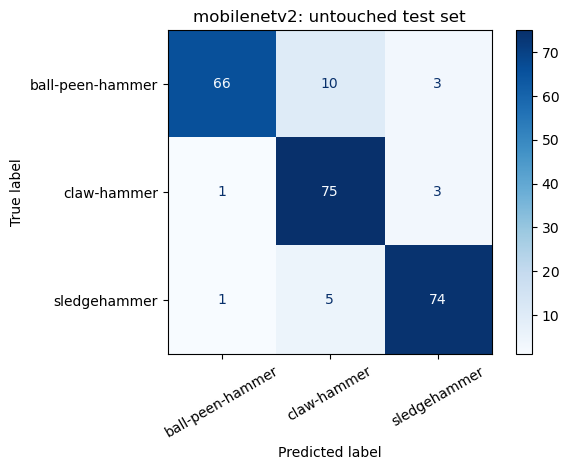

## Model: resnet50 — embeddings, probe fitting, and evaluation

,precision,recall,f1-score,support
ball-peen-hammer,0.9487,0.9367,0.9427,79.000
claw-hammer,0.9146,0.9494,0.9317,79.000
sledgehammer,0.9487,0.9250,0.9367,80.000
accuracy,0.9370,0.9370,0.9370,0.937
macro avg,0.9374,0.9370,0.9370,238.000
weighted avg,0.9374,0.9370,0.9370,238.000


,recall,support
ball-peen-hammer,0.936709,79.0
claw-hammer,0.949367,79.0
sledgehammer,0.925000,80.0


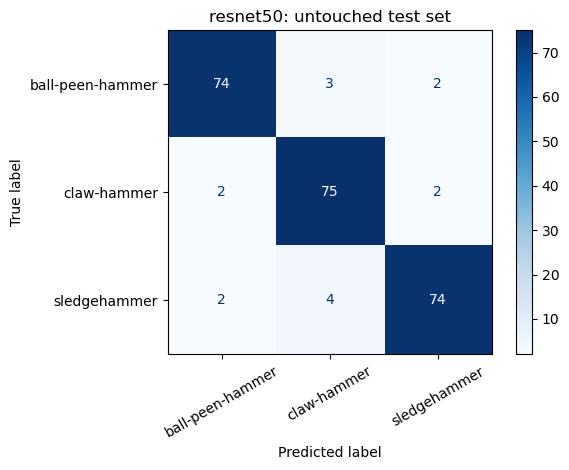

## Model: efficientnetv2m — embeddings, probe fitting, and evaluation

,precision,recall,f1-score,support
ball-peen-hammer,0.9481,0.9241,0.9359,79.0000
claw-hammer,0.9500,0.9620,0.9560,79.0000
sledgehammer,0.9383,0.9500,0.9441,80.0000
accuracy,0.9454,0.9454,0.9454,0.9454
macro avg,0.9454,0.9454,0.9453,238.0000
weighted avg,0.9454,0.9454,0.9453,238.0000


,recall,support
ball-peen-hammer,0.924051,79.0
claw-hammer,0.962025,79.0
sledgehammer,0.950000,80.0


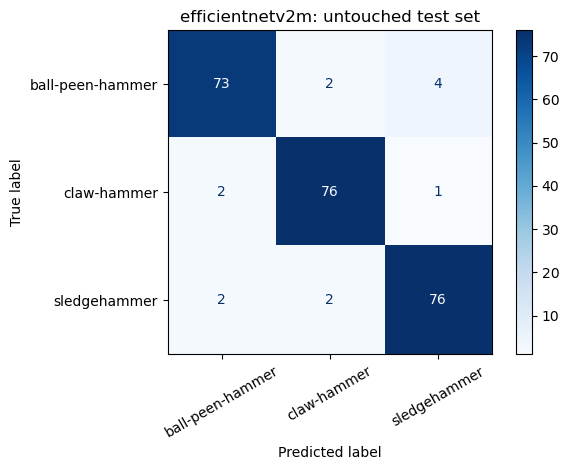

In [6]:
import gc

def embed(base, preprocess, images):
    # Batch inputs to avoid a full float32 copy of the image collection.
    vectors = []
    for start in range(0, len(images), config['batch_size']):
        batch = np.array(images[start:start+config['batch_size']], dtype='float32', copy=True)
        vectors.append(base(preprocess(batch), training=False).numpy())
    return np.concatenate(vectors)

comparison_rows = []
for name in config['applications']:
    display(Markdown(f'## Model: {name} — embeddings, probe fitting, and evaluation'))
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    base, preprocess = build_application(name, tuple(config['target_size']))
    assert len(base.trainable_weights) == 0
    before = hashlib.sha256()
    for weight in base.weights:
        before.update(weight.numpy().tobytes())
    _ = base(preprocess(np.array(X_train[:1], dtype='float32', copy=True)), training=False)
    embedding_start = time.perf_counter()
    E_original = embed(base, preprocess, X_train)
    E_augmented = embed(base, preprocess, X_augmented)
    E_test = embed(base, preprocess, X_test)
    embedding_seconds = time.perf_counter() - embedding_start
    E_fit = np.concatenate([E_original, E_augmented])
    probe = keras.Sequential([keras.Input((E_fit.shape[1],)),
                              keras.layers.Dense(len(class_names), activation='softmax')])
    probe.compile(optimizer=keras.optimizers.Adam(config['learning_rate']),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    start = time.perf_counter()
    history = probe.fit(E_fit, y_fit, epochs=config['epochs'], batch_size=config['batch_size'],
                        class_weight=class_weights, shuffle=True, verbose=0)
    train_seconds = time.perf_counter() - start
    probabilities = probe.predict(E_test, batch_size=config['batch_size'], verbose=0)
    prediction = probabilities.argmax(axis=1)
    report = classification_report(y_test, prediction, labels=classes,
                                    target_names=class_names, output_dict=True, zero_division=0)
    report_frame = pd.DataFrame(report).T
    cm = confusion_matrix(y_test, prediction, labels=classes)
    display(report_frame.round(4))
    display(report_frame.loc[class_names, ['recall','support']])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
    plt.title(name + ': untouched test set'); plt.tight_layout(); plt.show()
    after = hashlib.sha256()
    for weight in base.weights:
        after.update(weight.numpy().tobytes())
    assert before.hexdigest() == after.hexdigest(), 'Frozen backbone weights changed.'
    assert probe.count_params() == (E_fit.shape[1]+1)*len(class_names)
    comparison_rows.append({'application': name, 'backbone_parameters': base.count_params(),
                            'embedding_dimensions': E_fit.shape[1], 'embedding_seconds': embedding_seconds,
                            'probe_parameters': probe.count_params(), 'probe_training_seconds': train_seconds,
                            'test_accuracy': accuracy_score(y_test, prediction),
                            'macro_f1': f1_score(y_test, prediction, average='macro', zero_division=0)})
    probe.save(MODELS / f'P2_N3_{name}.keras')
    report_frame.to_csv(MODELS / f'P2_N3_{name}_classification_report.csv')
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(MODELS / f'P2_N3_{name}_confusion.csv')
    pd.DataFrame(history.history).to_csv(MODELS / f'P2_N3_{name}_history.csv', index=False)
    pd.DataFrame({'true': y_test, 'predicted': prediction}).to_csv(PREPARED / f'{name}_test_predictions.csv', index=False)
    del base, probe, E_original, E_augmented, E_test, E_fit
    gc.collect()
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(MODELS / 'P2_N3_comparison.csv', index=False)

#### Outcome - Test Performance and Class-Level Errors

All three applications completed their saved evaluation reports. Recomputing the following totals from the displayed confusion matrices reproduces the reported accuracies and macro-F1 values:

| Application | Correct | Errors | Accuracy | Macro-F1 |
|---|---:|---:|---:|---:|
| MobileNetV2 | 215 | 23 | 90.34% | 0.9035 |
| ResNet50 | 223 | 15 | 93.70% | 0.9370 |
| EfficientNetV2M | 225 | 13 | 94.54% | 0.9453 |

| Application | Ball-peen recall | Claw recall | Sledgehammer recall |
|---|---:|---:|---:|
| MobileNetV2 | 66/79 = 83.54% | 75/79 = 94.94% | 74/80 = 92.50% |
| ResNet50 | 74/79 = 93.67% | 75/79 = 94.94% | 74/80 = 92.50% |
| EfficientNetV2M | 73/79 = 92.41% | 76/79 = 96.20% | 76/80 = 95.00% |

**Interpretation:** MobileNetV2's main class-level weakness is ball-peen recall: **10 ball-peen images were labeled claw hammer** and three were labeled sledgehammer. Its ball-peen precision is high (0.9706), so the issue is missed ball-peen examples rather than many incorrect ball-peen predictions. ResNet50 substantially improves ball-peen recall while leaving the other two class recalls unchanged. EfficientNetV2M improves claw and sledgehammer recall but correctly recognizes one fewer ball-peen example than ResNet50. Higher overall accuracy therefore does not mean improvement for every class.

Rows in each confusion matrix represent true labels and columns predicted labels. In the raw pandas classification-report displays, the scalar `accuracy` is broadcast into every column, including the column headed `support`; that cell is a formatting artifact, not an image count. The actual evaluation support is **79 + 79 + 80 = 238** for every model.

### 6.1 Compare Model Size, Cost, and the Pre-model Confusion Prediction

**Task:** Relate observed test performance to measured extractor size and CPU extraction cost, then check the original confusion hypothesis.

**Decision:** Use the same recorded comparison table for all applications. Sum the two off-diagonal directions of each unordered class pair, and compare the worst observed pair with the predeclared **claw-hammer versus ball-peen-hammer** hypothesis.

**Steps taken:** Plot accuracy against measured backbone parameter count; identify each model's largest bidirectional confusion total; compare adjacent application sizes in accuracy and extraction time.

,application,backbone_parameters,embedding_dimensions,embedding_seconds,probe_parameters,probe_training_seconds,test_accuracy,macro_f1
0,mobilenetv2,2257984,1280,306.2499,3843,11.2233,0.9034,0.9035
1,resnet50,23587712,2048,1867.5234,6147,15.3861,0.9370,0.9370
2,efficientnetv2m,53150388,1280,2554.4391,3843,18.2369,0.9454,0.9453


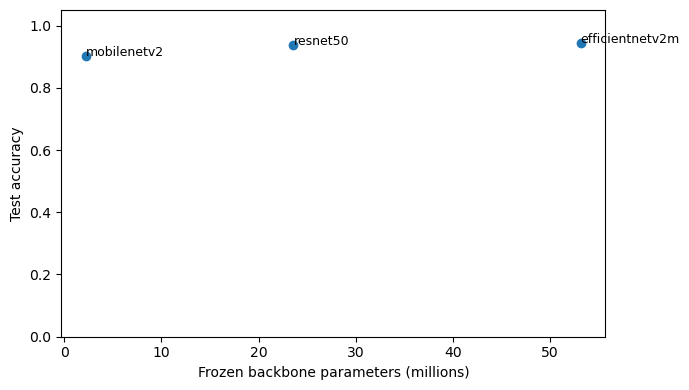

mobilenetv2 | maximum bidirectional confusion: 11 | pairs: [('ball-peen-hammer', 'claw-hammer')] | predicted pair among worst: True
resnet50 | maximum bidirectional confusion: 6 | pairs: [('claw-hammer', 'sledgehammer')] | predicted pair among worst: False
efficientnetv2m | maximum bidirectional confusion: 6 | pairs: [('ball-peen-hammer', 'sledgehammer')] | predicted pair among worst: False


**Measured size step:** mobilenetv2 → resnet50: accuracy difference = +3.36 percentage points; embedding time difference = +1561.3 seconds.

**Measured size step:** resnet50 → efficientnetv2m: accuracy difference = +0.84 percentage points; embedding time difference = +686.9 seconds.

In [7]:
display(comparison.round(4))
fig, axis = plt.subplots(figsize=(7,4))
axis.scatter(comparison.backbone_parameters/1e6, comparison.test_accuracy)
for row in comparison.itertuples():
    axis.annotate(row.application, (row.backbone_parameters/1e6, row.test_accuracy), fontsize=9)
axis.set(xlabel='Frozen backbone parameters (millions)', ylabel='Test accuracy', ylim=(0,1.05))
plt.tight_layout(); plt.show()
expected_pair = set(config['confusion_prediction'])
for name in config['applications']:
    cm = pd.read_csv(MODELS / f'P2_N3_{name}_confusion.csv', index_col=0).to_numpy()
    pairs = [(int(cm[i,j]+cm[j,i]), (class_names[i], class_names[j]))
             for i in range(len(class_names)) for j in range(i+1,len(class_names))]
    maximum = max(count for count, pair in pairs)
    worst_pairs = [pair for count, pair in pairs if count == maximum] if maximum else []
    print(name, '| maximum bidirectional confusion:', maximum, '| pairs:', worst_pairs,
          '| predicted pair among worst:', any(set(pair)==expected_pair for pair in worst_pairs))
ordered = comparison.sort_values('backbone_parameters')
for earlier, later in zip(ordered.to_dict('records'), ordered.to_dict('records')[1:]):
    display(Markdown(f"**Measured size step:** {earlier['application']} → {later['application']}: "
                    f"accuracy difference = {100*(later['test_accuracy']-earlier['test_accuracy']):+.2f} percentage points; "
                    f"embedding time difference = {later['embedding_seconds']-earlier['embedding_seconds']:+.1f} seconds."))
if comparison.test_accuracy.max() >= .98:
    display(Markdown('**Audit required:** near-perfect accuracy; investigate leakage and shortcuts in N2/N4.'))

#### Outcome - Measured Model-Size and Cost Comparison

| Application | Frozen backbone parameters | Embedding width | Trainable probe parameters | Embedding time (s) | Probe-fit time (s) |
|---|---:|---:|---:|---:|---:|
| MobileNetV2 | 2,257,984 | 1,280 | 3,843 | 156.6451 | 13.2855 |
| ResNet50 | 23,587,712 | 2,048 | 6,147 | 557.4929 | 14.3240 |
| EfficientNetV2M | 53,150,388 | 1,280 | 3,843 | 1,958.5697 | 17.4242 |

The extraction times are approximately **2.61, 9.29, and 32.64 minutes**. The small probe fits take approximately **13–17 seconds**, so frozen feature extraction dominates the measured workload. EfficientNetV2M and MobileNetV2 have the same trainable probe size because both output 1,280 features; ResNet50's 2,048 features require a larger Dense probe despite its smaller backbone than EfficientNetV2M.

| Size step | Accuracy change | Change in correct predictions | Extra extraction time | Extraction-time multiplier |
|---|---:|---:|---:|---:|
| MobileNetV2 → ResNet50 | +3.36 percentage points | +8 | +400.8 s | 3.56× |
| ResNet50 → EfficientNetV2M | +0.84 percentage points | +2 | +1,401.1 s | 3.51× |

Across the endpoints, EfficientNetV2M has approximately **23.54×** as many backbone parameters and **12.50×** the extraction time of MobileNetV2, with a **4.20-percentage-point** accuracy increase on this split. These ratios are descriptive, not estimates of app inference latency.

#### Outcome - Confusion-Hypothesis Check

| Application | Ball-peen ↔ claw | Ball-peen ↔ sledgehammer | Claw ↔ sledgehammer | Most-confused pair | Original prediction supported as the worst pair? |
|---|---:|---:|---:|---|---|
| MobileNetV2 | 11 | 4 | 8 | Ball-peen / claw | Yes |
| ResNet50 | 5 | 4 | 6 | Claw / sledgehammer | No |
| EfficientNetV2M | 4 | 6 | 3 | Ball-peen / sledgehammer | No |

**Observed tradeoff:** MobileNetV2 has the lowest measured extraction cost, EfficientNetV2M has the highest recorded aggregate scores, and ResNet50 occupies the middle cost/performance position. The final size increase costs about **23.35 extra minutes of CPU extraction for two additional correct predictions**. That is diminishing measured return in this run; it does not establish that the two-image advantage is statistically reliable or that any model is the final deployment choice. No repeated-seed, paired significance, validation-selection, or app-latency result is shown. 

### 7.1 Export Mapping, Preprocessing Contract, and Model Fingerprints

**Task:** Preserve the trained probes and the information needed to reconstruct their exact inputs and class order.

**Decision:** Save the small Dense probes separately from the frozen ImageNet applications, and copy Notebook 2's label mapping and preprocessing metadata beside them.

**Steps taken:** Save one `.keras` probe per application; retain classification reports, confusion matrices, histories, and the comparison CSV; copy the exact mapping and geometry metadata; write training metadata with library/runtime versions, configured settings, class weights, augmentation checksum, and configuration/preprocessing/probe checksums. Check every probe file against the source code's **100,000,000-byte** size threshold.

In [8]:
import shutil, platform
shutil.copy2(PREPARED / 'label_to_index.json', MODELS / 'label_to_index.json')
shutil.copy2(PREPARED / 'preprocessing.json', MODELS / 'preprocessing.json')
model_files = {name: f'P2_N3_{name}.keras' for name in config['applications']}
for filename in model_files.values():
    assert (MODELS / filename).stat().st_size < 100_000_000
save_json(MODELS / 'training_metadata.json', {
    'applications': config['applications'], 'class_weights': class_weights,
    'config_sha256': digest(ROOT / 'config/project.json'),
    'preprocessing_sha256': digest(PREPARED / 'preprocessing.json'),
    'probe_sha256': {name: digest(MODELS / filename) for name, filename in model_files.items()},
    'python': platform.python_version(), 'tensorflow': tf.__version__, 'keras': keras.__version__,
    'epochs': config['epochs'], 'batch_size': config['batch_size'], 'learning_rate': config['learning_rate'],
    'augmentation_sha256': digest(augmented_path), 'test_set_used_for_tuning': False})
print('Saved probes:', list(model_files.values()))

Saved probes: ['P2_N3_mobilenetv2.keras', 'P2_N3_resnet50.keras', 'P2_N3_efficientnetv2m.keras']


#### Outcome - Saved Models and Reproducibility Handoff

The final saved output confirms these three probe filenames:

- `P2_N3_mobilenetv2.keras`
- `P2_N3_resnet50.keras`
- `P2_N3_efficientnetv2m.keras`

The final cell completed without a saved error after its model-size assertions and metadata write. The source also copies **`label_to_index.json`** and **`preprocessing.json`** into `models/` and writes **`training_metadata.json`**. Earlier source cells write each classification-report, confusion, and history CSV, the **`P2_N3_comparison.csv`** table, and per-application test-prediction CSVs under the external prepared-data folder. 

**Interpretation:** Use each probe only with its matching frozen application, application-specific scaling, and the saved mapping **ball-peen-hammer → 0, claw-hammer → 1, sledgehammer → 2**. The recorded model scores remain attached to this run's specific 948/238 split.